# Projeto completo — Variabilidade do plano de produção e estoque de segurança por Part Number
**Piloto sintético MAQ-001 | 13 PNs | 3 fornecedores fictícios | Lead time 5 meses**

**Estrutura restaurada do projeto original:** trajetória de revisões, LT × final, variabilidade pós-LT, datasheet de PNs, dashboard, simulação de estoque de segurança, relatório PDF executivo e módulo complementar de Machine Learning.

Execute todas as células no Colab e selecione a planilha sintética. Todos os valores e resultados são simulados; não representam indicadores reais da empresa.

**Regra temporal (atualizada):** por padrão, a data de corte é a data da execução; meses de produção no mês corrente ou posteriores não são usados como resultados finais. Os resultados e as métricas variam conforme o corte.


## Guia rápido — como substituir os dados sintéticos por dados empresariais

**Antes de executar:** utilize a planilha-modelo e leia `GUIA_APLICACAO_EMPRESARIAL.md`. Atualize os **valores das linhas**, não os cabeçalhos. Na aba `L'On`, preencha `Modelo`, `Data da revisão`, `Mês de produção`, `Meses até produção` e `Plano de máquinas`. Nas três abas de PNs, atualize `PN sintético`, `Modelo sintético`, `Qtd por máquina`, `Lead time (meses)` e `Fornecedor fictício`.

**Parâmetros fixos no notebook:** altere `MODELO` e `LT_MESES` na primeira célula de código, quando necessário. Os nomes de abas `L'On`, `FORN-A`, `FORN-B` e `FORN-C` devem ser mantidos nesta versão. Todos os PNs precisam ter o mesmo LT.

**Regras obrigatórias:** um registro por mês de produção e horizonte; datas coerentes; quantidades inteiras não negativas; uma revisão exatamente no LT e outra no horizonte 0. Sem esses registros, o mês não será elegível.

**Como ler os resultados:** o ES baseado no **aumento final** não é o mesmo que a exposição ao **pico pós-LT**. Consulte ambos no painel e na matriz de cobertura. A cobertura é histórica e o ML é experimental; valide decisões com as áreas responsáveis. **Não publique dados reais confidenciais no GitHub.**


## Plano de validação futura com dados reais

**Situação:** o ML é um experimento de viabilidade, ainda não uma previsão validada para compras. A cobertura calculada é retrospectiva.

**Coletar:** histórico datado de cada revisão por mês de produção (incluindo revisão no LT e plano final), volume efetivamente produzido, PNs e consumo por máquina, lead time planejado e realizado por PN/fornecedor, pedidos e datas de entrega, estoque disponível, faltas, urgências e custo de manter estoque ou parar produção. Guardar a versão e a origem das extrações.

**Testar:** (1) integridade e ausência de vazamento temporal; (2) comparação com baseline e política empírica em múltiplas janelas temporais futuras (*walk-forward*); (3) MAE/RMSE, viés, taxa de cobertura, faltas, excesso de estoque e custo; (4) estabilidade por período, máquina, PN e fornecedor; (5) sensibilidade a revisões ausentes e LT variável; (6) piloto em paralelo (*shadow mode*) sem influenciar compras, seguido de aprovação conjunta de Planejamento, Compras, Logística e TI.

**Critério de liberação:** definir previamente metas de desempenho e risco com a empresa. Não ativar recomendações automáticas se o modelo não superar a referência simples ou se não houver evidência de cobertura e custo aceitáveis em dados reais fora da amostra.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ARQUIVO = 'Planilha_Modelo_MAQ-001_ORIENTADA(1).xlsx'  # No Colab, envie esta planilha quando solicitado
MODELO = 'MAQ-001'
LT_MESES = 5
# Data de corte: padrão = data de execução. Pode ser alterada para auditorias retrospectivas.
# Exemplo: DATA_CORTE = '2026-09-30'. Não avance artificialmente a data para dados reais.
DATA_CORTE = pd.Timestamp.today().normalize()
DATA_CORTE = pd.Timestamp(DATA_CORTE).normalize()
MES_CORTE = DATA_CORTE.to_period('M').to_timestamp()
ULTIMO_MES_ENCERRADO = MES_CORTE - pd.DateOffset(months=1)
print(f'Data de corte: {DATA_CORTE.date()} | último mês encerrado: {ULTIMO_MES_ENCERRADO:%m/%Y}')

if not os.path.isfile(ARQUIVO):
    try:
        from google.colab import files
        print('Selecione a planilha sintética...')
        carregados = files.upload()
        ARQUIVO = next(iter(carregados))
    except ImportError:
        raise FileNotFoundError('Coloque a planilha na mesma pasta do notebook ou execute no Google Colab.')
print('Arquivo:', ARQUIVO)

Data de corte: 2026-10-20 | último mês encerrado: 09/2026
Selecione a planilha sintética...


Saving Planilha_Modelo_MAQ-001_ORIENTADA(1)[1].xlsx to Planilha_Modelo_MAQ-001_ORIENTADA(1)[1].xlsx
Arquivo: Planilha_Modelo_MAQ-001_ORIENTADA(1)[1].xlsx


## 1. Importação e validação da estrutura
Lemos a aba de revisões e as três abas de fornecedores. Os identificadores de fornecedores e PNs são fictícios.

In [ ]:
revisoes = pd.read_excel(ARQUIVO, sheet_name="L'On")
abas_pn = ['FORN-A', 'FORN-B', 'FORN-C']
pns = pd.concat([pd.read_excel(ARQUIVO, sheet_name=aba).assign(Aba_origem=aba) for aba in abas_pn], ignore_index=True)
col_rev = ['Modelo','Data da revisão','Mês de produção','Meses até produção','Plano de máquinas']
col_pn = ['PN sintético','Modelo sintético','Qtd por máquina','Lead time (meses)']
assert set(col_rev).issubset(revisoes.columns), 'Colunas faltantes na aba de planejamento.'
assert set(col_pn).issubset(pns.columns), 'Colunas faltantes nas abas de PN.'
for c in ['Data da revisão','Mês de produção']:
    revisoes[c] = pd.to_datetime(revisoes[c], errors='coerce').dt.to_period('M').dt.to_timestamp()
for c in ['Meses até produção','Plano de máquinas']:
    revisoes[c] = pd.to_numeric(revisoes[c], errors='coerce')
revisoes = revisoes.loc[revisoes['Modelo'].eq(MODELO)].copy()
pns = pns.loc[pns['Modelo sintético'].eq(MODELO)].copy()
assert revisoes[col_rev].notna().all().all(), 'Há dados obrigatórios ausentes nas revisões.'
assert revisoes['Plano de máquinas'].ge(0).all(), 'Plano negativo encontrado.'
assert revisoes['Plano de máquinas'].mod(1).eq(0).all(), 'Plano deve ser inteiro.'
assert pns['PN sintético'].is_unique, 'PN duplicado.'
assert pns['Qtd por máquina'].gt(0).all(), 'Consumo por máquina inválido.'
assert pns['Lead time (meses)'].eq(LT_MESES).all(), 'Há PNs com LT diferente do piloto.'
assert not revisoes.duplicated(['Mês de produção','Meses até produção']).any(), 'Revisões duplicadas por mês e horizonte.'
lead_calculado = (revisoes['Mês de produção'].dt.year - revisoes['Data da revisão'].dt.year)*12 + (revisoes['Mês de produção'].dt.month - revisoes['Data da revisão'].dt.month)
assert lead_calculado.eq(revisoes['Meses até produção']).all(), 'Horizonte incompatível com as datas.'
# Nunca usar revisões com data posterior à data de corte.
revisoes_futuras_na_planilha = revisoes.loc[revisoes['Data da revisão'] > MES_CORTE].copy()
revisoes = revisoes.loc[revisoes['Data da revisão'] <= MES_CORTE].copy()
print(f'Revisões futuras (após mês da data de corte) ignoradas: {len(revisoes_futuras_na_planilha)}')
print(f'Revisões: {len(revisoes)} | Meses: {revisoes["Mês de produção"].nunique()} | PNs: {len(pns)}')
display(revisoes.head(3), pns[['PN sintético','Fornecedor fictício','Qtd por máquina','Lead time (meses)']].head())

Revisões futuras (após mês da data de corte) ignoradas: 3
Revisões: 237 | Meses: 24 | PNs: 13


,Modelo,Data da revisão,Mês de produção,Meses até produção,Plano de máquinas,Tipo de dado
0,MAQ-001,2024-04-01,2025-01-01,9,6,SINTÉTICO
1,MAQ-001,2024-05-01,2025-01-01,8,3,SINTÉTICO
2,MAQ-001,2024-06-01,2025-01-01,7,3,SINTÉTICO


,PN sintético,Fornecedor fictício,Qtd por máquina,Lead time (meses)
0,PN-0001,FORN-A,1,5
1,PN-0002,FORN-A,1,5
2,PN-0003,FORN-A,1,5
3,PN-0004,FORN-A,1,5
4,PN-0005,FORN-B,1,5


## 2. Plano no LT, situação temporal e consolidação

Para cada mês de produção, o plano no horizonte do LT é a referência de compra. **O histórico sintético de 2025 (12 meses) é incluído integralmente**, assim como os meses encerrados de 2026. Em uma execução durante outubro de 2026, são 12 meses de 2025 e 9 meses de 2026 (janeiro a setembro), totalizando 21 meses elegíveis antes das defasagens de ML. **Somente meses de produção anteriores ao mês da data de corte**, com uma revisão de horizonte zero disponível, são considerados consolidados para cálculo de cobertura histórica e treinamento/avaliação do ML. Meses em andamento ou futuros são exibidos separadamente, sem variável-alvo final conhecida. Em dados reais, o encerramento do mês e a equivalência entre plano consolidado e produção realizada devem ser confirmados pela operação. Na base sintética, o fechamento é uma regra demonstrativa de calendário.


In [ ]:
tabela = revisoes.pivot(index='Mês de produção', columns='Meses até produção', values='Plano de máquinas').sort_index()
assert LT_MESES in tabela.columns, 'Não há revisões com LT de 5 meses.'
plan_lt = tabela[LT_MESES].rename('Plano_LT')
ultimas = (revisoes.sort_values(['Mês de produção','Meses até produção'])
           .drop_duplicates('Mês de produção', keep='first')
           .set_index('Mês de produção'))
resumo = pd.concat([plan_lt, ultimas['Plano de máquinas'].rename('Ultimo_plano_disponivel'),
                    ultimas['Meses até produção'].rename('Horizonte_ultimo')], axis=1)
resumo['Situacao'] = np.select(
    [resumo.index < MES_CORTE, resumo.index == MES_CORTE],
    ['Mês encerrado', 'Mês em andamento'], default='Mês futuro')
resumo['Tem_referencia_LT'] = resumo['Plano_LT'].notna()
resumo['Tem_fechamento'] = resumo['Horizonte_ultimo'].eq(0)
resumo['Elegível'] = (resumo['Situacao'].eq('Mês encerrado') &
                     resumo['Tem_referencia_LT'] & resumo['Tem_fechamento'])
print(f'Meses consolidados elegíveis: {int(resumo["Elegível"].sum())} de {len(resumo)}')
print('Meses em andamento/futuros ou sem fechamento (não entram em ES histórico nem no ML):')
display(resumo.loc[~resumo['Elegível']])
# Acompanhamento de meses abertos: diferença PROVISÓRIA, nunca rotulada como realizada.
acompanhamento = resumo.loc[~resumo['Elegível']].copy()
acompanhamento['Variacao_provisoria'] = (acompanhamento['Ultimo_plano_disponivel'] -
                                        acompanhamento['Plano_LT'])
base = resumo.loc[resumo['Elegível'], ['Plano_LT','Ultimo_plano_disponivel']].copy()
base = base.rename(columns={'Ultimo_plano_disponivel':'Plano_final'})
assert not base.empty, 'Nenhum mês encerrado e elegível. Confira a data de corte.'
base['Variacao_final'] = base['Plano_final'] - base['Plano_LT']
base['Aumento_final'] = base['Variacao_final'].clip(lower=0)
base['Reducao_final'] = (-base['Variacao_final']).clip(lower=0)
display(base.round(2))


Meses consolidados elegíveis: 21 de 24
Meses em andamento/futuros ou sem fechamento (não entram em ES histórico nem no ML):


,Plano_LT,Ultimo_plano_disponivel,Horizonte_ultimo,Situacao,Tem_referencia_LT,Tem_fechamento,Elegível
Mês de produção,,,,,,,
2026-10-01,7.0,6,0,Mês em andamento,True,True,False
2026-11-01,7.0,6,1,Mês futuro,True,False,False
2026-12-01,3.0,2,2,Mês futuro,True,False,False


,Plano_LT,Plano_final,Variacao_final,Aumento_final,Reducao_final
Mês de produção,,,,,
2025-01-01,2.0,4,2.0,2.0,0.0
2025-02-01,7.0,6,-1.0,0.0,1.0
2025-03-01,8.0,7,-1.0,0.0,1.0
2025-04-01,4.0,4,0.0,0.0,-0.0
2025-05-01,4.0,5,1.0,1.0,0.0
2025-06-01,3.0,2,-1.0,0.0,1.0
2025-07-01,1.0,3,2.0,2.0,0.0
2025-08-01,4.0,4,0.0,0.0,-0.0
2025-09-01,7.0,5,-2.0,0.0,2.0


In [ ]:
# Auditoria: meses históricos elegíveis por ano (2025 também participa da análise)
contagem_ano = (resumo.loc[resumo['Elegível']].groupby(resumo.loc[resumo['Elegível']].index.year).size())
print('Meses consolidados por ano:')
print(contagem_ano.rename_axis('Ano').to_string())
print('Meses futuros/em andamento excluídos:')
print(resumo.loc[~resumo['Elegível'], ['Situacao','Tem_referencia_LT','Tem_fechamento']].to_string())

Meses consolidados por ano:
Ano
2025    12
2026     9
Meses futuros/em andamento excluídos:
                         Situacao  Tem_referencia_LT  Tem_fechamento
Mês de produção                                                     
2026-10-01       Mês em andamento               True            True
2026-11-01             Mês futuro               True           False
2026-12-01             Mês futuro               True           False


## 3. Variabilidade das revisões posteriores ao LT
O **pico pós-LT** é a maior quantidade planejada observada após a decisão de compra. Ele pode superar a necessidade final, caso o plano seja reduzido posteriormente. Os dois indicadores são apresentados separadamente.

Aumentos finais: 6 meses
Aumentos em algum ponto após LT: 9 meses
Média da variação final: -0.29


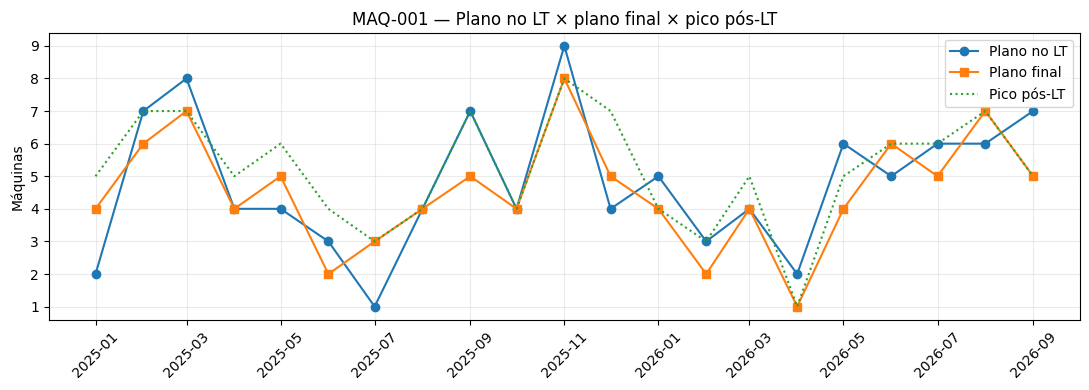

In [ ]:
pos_lt = revisoes[revisoes['Meses até produção'].between(0, LT_MESES-1)].copy()
picos = pos_lt.groupby('Mês de produção')['Plano de máquinas'].max().rename('Pico_pos_LT')
base = base.join(picos)
base['Aumento_pico'] = (base['Pico_pos_LT'] - base['Plano_LT']).clip(lower=0)
print('Aumentos finais:', int(base['Aumento_final'].gt(0).sum()), 'meses')
print('Aumentos em algum ponto após LT:', int(base['Aumento_pico'].gt(0).sum()), 'meses')
print('Média da variação final:', round(base['Variacao_final'].mean(),2))
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(base.index, base['Plano_LT'], marker='o', label='Plano no LT')
ax.plot(base.index, base['Plano_final'], marker='s', label='Plano final')
ax.plot(base.index, base['Pico_pos_LT'], linestyle=':', label='Pico pós-LT')
ax.set(title='MAQ-001 — Plano no LT × plano final × pico pós-LT', ylabel='Máquinas')
ax.legend(); ax.grid(alpha=.25); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 3A. Trajetória completa e indicadores de variabilidade pós-LT

Como no relatório original, analisamos **mínimo, máximo (pico), amplitude e aumento máximo em relação ao plano no LT**, além da variação final. O pico é um **indicador de volatilidade**, não uma falta efetivamente ocorrida. O último plano disponível tampouco comprova consumo realizado.


Indicadores de variabilidade pós-LT:


,Indicador,Resultado
0,Amplitude média pós-LT,1.57
1,Maior amplitude observada,3
2,Aumento máximo positivo médio,0.71
3,Maior aumento pós-LT,3
4,Meses com aumento pós-LT,9 de 21
5,Demanda surgindo após LT,0


,Plano_LT,Min_pos_LT,Pico_pos_LT,Amplitude_pos_LT,Aumento_maximo_pos_LT,Plano_final,Erro_LT_Final
Mês de produção,,,,,,,
2025-01-01,2.0,2,5,3,3.0,4,2.0
2025-02-01,7.0,5,7,2,0.0,6,-1.0
2025-03-01,8.0,6,7,1,0.0,7,-1.0
2025-04-01,4.0,3,5,2,1.0,4,0.0
2025-05-01,4.0,4,6,2,2.0,5,1.0
2025-06-01,3.0,2,4,2,1.0,2,-1.0
2025-07-01,1.0,1,3,2,2.0,3,2.0
2025-08-01,4.0,3,4,1,0.0,4,0.0
2025-09-01,7.0,5,7,2,0.0,5,-2.0


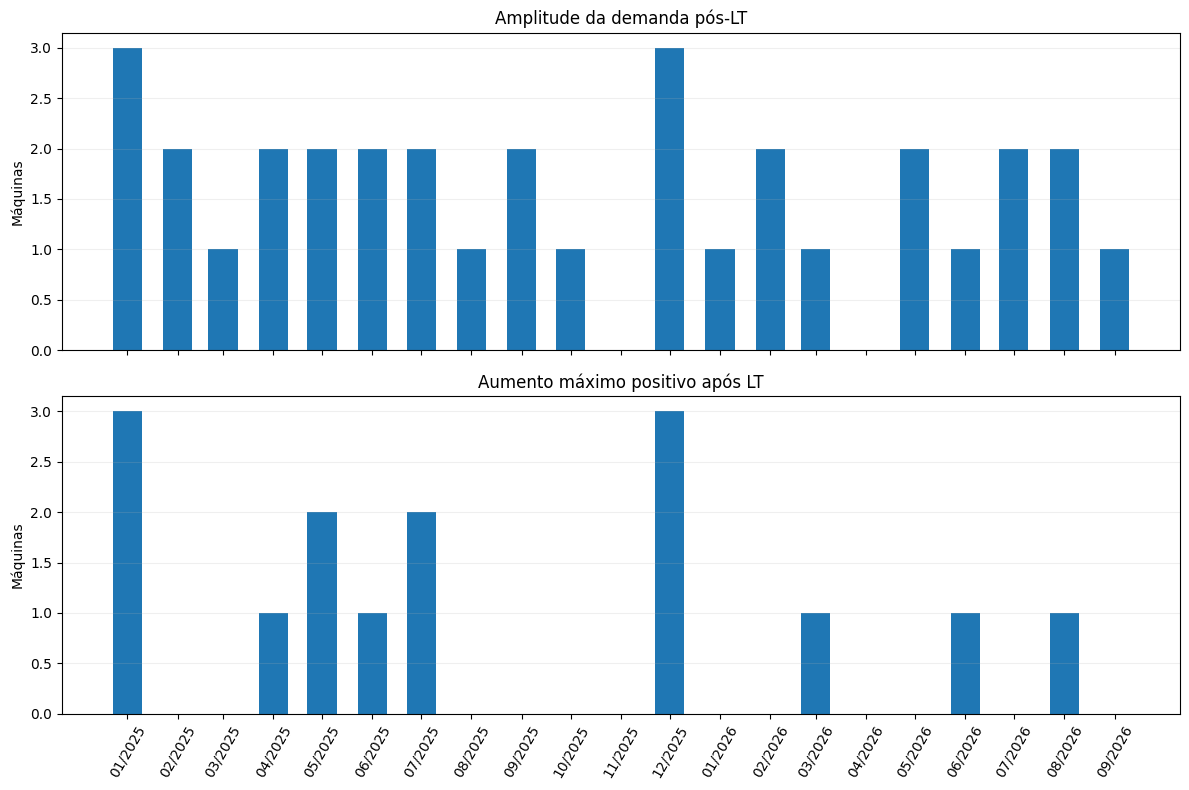

In [ ]:
# Trajetória a partir do plano de referência no LT, incluindo as revisões seguintes.
traj = revisoes[revisoes['Meses até produção'].between(0, LT_MESES)].copy()
minimos = traj.groupby('Mês de produção')['Plano de máquinas'].min().rename('Min_pos_LT')
base = base.join(minimos)
base['Amplitude_pos_LT'] = base['Pico_pos_LT'] - base['Min_pos_LT']
base['Aumento_maximo_pos_LT'] = (base['Pico_pos_LT'] - base['Plano_LT']).clip(lower=0)
base['Erro_LT_Final'] = base['Plano_final'] - base['Plano_LT']
indicadores = pd.DataFrame({
    'Indicador':['Amplitude média pós-LT','Maior amplitude observada','Aumento máximo positivo médio','Maior aumento pós-LT','Meses com aumento pós-LT','Demanda surgindo após LT'],
    'Resultado':[round(base['Amplitude_pos_LT'].mean(),2),int(base['Amplitude_pos_LT'].max()),round(base['Aumento_maximo_pos_LT'].mean(),2),int(base['Aumento_maximo_pos_LT'].max()),f"{int(base['Aumento_maximo_pos_LT'].gt(0).sum())} de {len(base)}",int(((base['Plano_LT']==0)&(base['Pico_pos_LT']>0)).sum())]
})
print('Indicadores de variabilidade pós-LT:')
display(indicadores)
trajetoria_mensal = base[['Plano_LT','Min_pos_LT','Pico_pos_LT','Amplitude_pos_LT','Aumento_maximo_pos_LT','Plano_final','Erro_LT_Final']].copy()
display(trajetoria_mensal)
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
axes[0].bar(base.index,base['Amplitude_pos_LT'],width=18,label='Amplitude')
axes[0].set(title='Amplitude da demanda pós-LT',ylabel='Máquinas');axes[0].grid(axis='y',alpha=.2)
axes[1].bar(base.index,base['Aumento_maximo_pos_LT'],width=18,label='Aumento máximo pós-LT')
axes[1].set(title='Aumento máximo positivo após LT',ylabel='Máquinas');axes[1].grid(axis='y',alpha=.2)
plt.xticks(base.index,[d.strftime('%m/%Y') for d in base.index],rotation=60);plt.tight_layout();plt.show()


## 4. Demanda por PN
Cada PN possui consumo de uma unidade por máquina nesta versão. **Os 13 PNs compartilham o mesmo histórico de produção; não são 13 observações estatísticas independentes.**

In [ ]:
demanda = base.reset_index().merge(pns[['PN sintético','Fornecedor fictício','Qtd por máquina']], how='cross')
for nome, coluna in [('Demanda_LT','Plano_LT'),('Demanda_final','Plano_final'),('Demanda_pico','Pico_pos_LT'),('Aumento_final_PN','Aumento_final'),('Aumento_pico_PN','Aumento_pico')]:
    demanda[nome] = demanda[coluna] * demanda['Qtd por máquina']
print('Linhas PN-mês:', len(demanda), '(não independentes)')
display(demanda[['Mês de produção','PN sintético','Demanda_LT','Demanda_final','Aumento_final_PN','Aumento_pico_PN']].head(15))

Linhas PN-mês: 273 (não independentes)


,Mês de produção,PN sintético,Demanda_LT,Demanda_final,Aumento_final_PN,Aumento_pico_PN
0,2025-01-01,PN-0001,2.0,4,2.0,3.0
1,2025-01-01,PN-0002,2.0,4,2.0,3.0
2,2025-01-01,PN-0003,2.0,4,2.0,3.0
3,2025-01-01,PN-0004,2.0,4,2.0,3.0
4,2025-01-01,PN-0005,2.0,4,2.0,3.0
5,2025-01-01,PN-0006,2.0,4,2.0,3.0
6,2025-01-01,PN-0007,2.0,4,2.0,3.0
7,2025-01-01,PN-0008,2.0,4,2.0,3.0
8,2025-01-01,PN-0009,2.0,4,2.0,3.0
9,2025-01-01,PN-0010,2.0,4,2.0,3.0


## 4A. Data sheet de Part Numbers e dashboard interativo

A ficha técnica mostra PN fictício, fornecedor fictício, aplicação, quantidade por máquina e lead time. O dashboard permite selecionar um PN, visualizar a trajetória LT × pico × final e consultar a tabela mensal. Todos os 13 PNs possuem consumo unitário e compartilham a mesma trajetória de máquinas.


In [ ]:
from IPython.display import display, HTML
try:
    import ipywidgets as widgets
    _widgets_ok = True
except ImportError:
    _widgets_ok = False

datasheet = pns[['PN sintético','Modelo sintético','Fornecedor fictício','Descrição genérica','Qtd por máquina','Lead time (meses)']].copy()
datasheet.columns=['Part Number','Aplicação','Fornecedor','Descrição','Qtd./máquina','Lead time (meses)']
print('DATA SHEET — 13 PNs sintéticos:')
display(datasheet)

def dashboard_pn(pn):
    pn_info = pns.loc[pns['PN sintético'].eq(pn)].iloc[0]
    qtd = float(pn_info['Qtd por máquina'])
    mensal = trajetoria_mensal.copy()*qtd
    fig, ax = plt.subplots(figsize=(11,4))
    ax.plot(mensal.index,mensal['Plano_LT'],marker='o',label='Demanda no LT')
    ax.plot(mensal.index,mensal['Pico_pos_LT'],marker='^',label='Pico pós-LT')
    ax.plot(mensal.index,mensal['Plano_final'],marker='s',label='Demanda final')
    ax.set(title=f'Trajetória da demanda — {pn} | {pn_info["Fornecedor fictício"]}',ylabel='Peças',xlabel='Mês de produção')
    ax.legend();ax.grid(alpha=.25);plt.xticks(rotation=45);plt.tight_layout();plt.show()
    print('Indicadores:', 'Maior aumento pós-LT:',int(mensal['Aumento_maximo_pos_LT'].max()),'peças;',
          'Meses com aumento:',int(mensal['Aumento_maximo_pos_LT'].gt(0).sum()),'de',len(mensal))
    display(mensal.rename(columns={'Plano_LT':'LT','Min_pos_LT':'Mín.','Pico_pos_LT':'Pico','Amplitude_pos_LT':'Amplitude','Aumento_maximo_pos_LT':'Aumento máx.','Plano_final':'Final','Erro_LT_Final':'Erro LT→Final'}).round(1))

if _widgets_ok:
    display(widgets.interact(dashboard_pn,pn=widgets.Dropdown(options=datasheet['Part Number'].tolist(),description='PN:')))
else:
    print('Widgets não disponíveis; exibindo PN de referência.')
    dashboard_pn(datasheet['Part Number'].iloc[0])


DATA SHEET — 13 PNs sintéticos:


,Part Number,Aplicação,Fornecedor,Descrição,Qtd./máquina,Lead time (meses)
0,PN-0001,MAQ-001,FORN-A,COMPONENTE-01,1,5
1,PN-0002,MAQ-001,FORN-A,COMPONENTE-02,1,5
2,PN-0003,MAQ-001,FORN-A,COMPONENTE-03,1,5
3,PN-0004,MAQ-001,FORN-A,COMPONENTE-04,1,5
4,PN-0005,MAQ-001,FORN-B,COMPONENTE-05,1,5
5,PN-0006,MAQ-001,FORN-B,COMPONENTE-06,1,5
6,PN-0007,MAQ-001,FORN-B,COMPONENTE-07,1,5
7,PN-0008,MAQ-001,FORN-B,COMPONENTE-08,1,5
8,PN-0009,MAQ-001,FORN-B,COMPONENTE-09,1,5
9,PN-0010,MAQ-001,FORN-C,COMPONENTE-10,1,5


interactive(children=(Dropdown(description='PN:', options=('PN-0001', 'PN-0002', 'PN-0003', 'PN-0004', 'PN-000…

<function __main__.dashboard_pn(pn)>

## 5. Simulação empírica de estoque de segurança
Para cada ES candidato, calculamos a **cobertura histórica**: proporção de meses em que o ES foi suficiente para cobrir o aumento final após LT. Isso não equivale a um nível de serviço futuro garantido. Também avaliamos o cenário conservador do pico pós-LT.

,ES_maquinas,Cobertura_final_%,Cobertura_pico_%,Faltas_finais_total,Excesso_vs_aumento_final_total
0,0,71.4,57.1,8,0
1,1,90.5,81.0,2,15
2,2,100.0,90.5,0,34
3,3,100.0,100.0,0,55


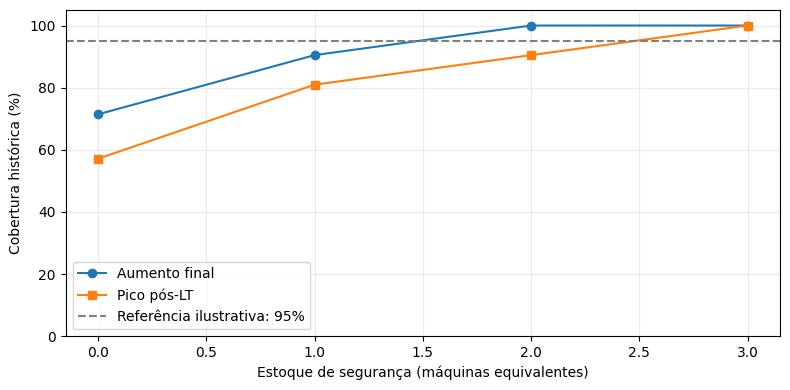

In [ ]:
limite = int(max(base['Aumento_final'].max(),base['Aumento_pico'].max(),0))
politicas=[]
for es in range(limite+1):
    politicas.append({'ES_maquinas':es,
       'Cobertura_final_%':100*(base['Aumento_final']<=es).mean(),
       'Cobertura_pico_%':100*(base['Aumento_pico']<=es).mean(),
       'Faltas_finais_total':int((base['Aumento_final']-es).clip(lower=0).sum()),
       'Excesso_vs_aumento_final_total':int((es-base['Aumento_final']).clip(lower=0).sum())})
politicas=pd.DataFrame(politicas)
display(politicas.round(1))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(politicas['ES_maquinas'],politicas['Cobertura_final_%'],marker='o',label='Aumento final')
ax.plot(politicas['ES_maquinas'],politicas['Cobertura_pico_%'],marker='s',label='Pico pós-LT')
ax.axhline(95,linestyle='--',color='gray',label='Referência ilustrativa: 95%')
ax.set(xlabel='Estoque de segurança (máquinas equivalentes)',ylabel='Cobertura histórica (%)',ylim=(0,105))
ax.legend();ax.grid(alpha=.25);plt.tight_layout();plt.show()

## 5A. Base estatística, curva de risco e estoque de segurança por PN

A política principal de ES cobre o **aumento final não negativo** após o LT. A curva de picos pós-LT permanece como análise complementar, conforme o notebook original. A cobertura é **histórica e empírica**, não garantia de nível de serviço futuro.


Distribuição observada dos aumentos finais:


,Meses
Aumento (un.),
0.0,15
1.0,4
2.0,2


ES demonstrativo em máquinas equivalentes: 2 | cobertura histórica: 100.0 %
NÃO é recomendação de compra nem promessa de nível de serviço de 95%.


,PN sintético,Fornecedor fictício,Qtd por máquina,ES_simulado_un,Cobertura_historica_%
0,PN-0001,FORN-A,1,2,100.0
1,PN-0002,FORN-A,1,2,100.0
2,PN-0003,FORN-A,1,2,100.0
3,PN-0004,FORN-A,1,2,100.0
4,PN-0005,FORN-B,1,2,100.0
5,PN-0006,FORN-B,1,2,100.0
6,PN-0007,FORN-B,1,2,100.0
7,PN-0008,FORN-B,1,2,100.0
8,PN-0009,FORN-B,1,2,100.0
9,PN-0010,FORN-C,1,2,100.0


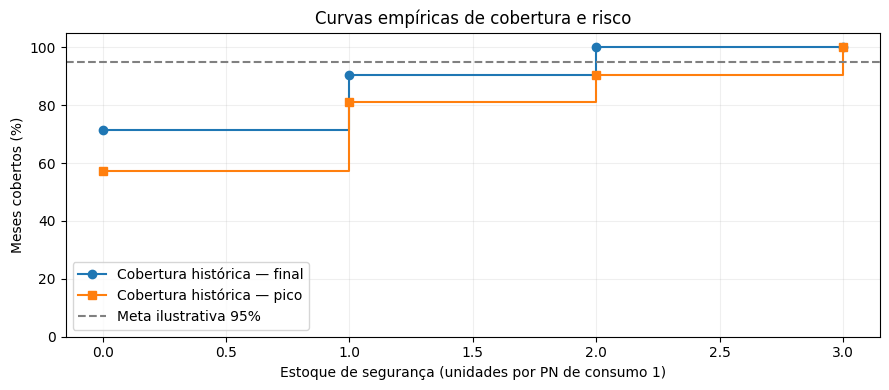

In [ ]:
base_es = base[['Plano_LT','Plano_final','Variacao_final','Aumento_final','Aumento_pico','Amplitude_pos_LT']].copy()
print('Distribuição observada dos aumentos finais:')
display(base_es['Aumento_final'].value_counts().sort_index().rename_axis('Aumento (un.)').to_frame('Meses'))
politicas_pn = demanda[['PN sintético','Fornecedor fictício','Qtd por máquina']].drop_duplicates().copy()
# Critério demonstrativo: menor ES que cobre pelo menos 95% dos meses históricos.
ALVO_COBERTURA = 95
candidatos = politicas.loc[politicas['Cobertura_final_%']>=ALVO_COBERTURA]
es_demo = int(candidatos.iloc[0]['ES_maquinas']) if not candidatos.empty else int(politicas['ES_maquinas'].max())
politicas_pn['ES_simulado_un'] = politicas_pn['Qtd por máquina']*es_demo
politicas_pn['Cobertura_historica_%'] = 100*(base['Aumento_final']<=es_demo).mean()
print('ES demonstrativo em máquinas equivalentes:',es_demo,'| cobertura histórica:',round(politicas_pn['Cobertura_historica_%'].iloc[0],1),'%')
print('NÃO é recomendação de compra nem promessa de nível de serviço de 95%.')
display(politicas_pn)
fig,ax=plt.subplots(figsize=(9,4))
ax.step(politicas['ES_maquinas'],politicas['Cobertura_final_%'],where='post',marker='o',label='Cobertura histórica — final')
ax.step(politicas['ES_maquinas'],politicas['Cobertura_pico_%'],where='post',marker='s',label='Cobertura histórica — pico')
ax.axhline(ALVO_COBERTURA,linestyle='--',color='gray',label='Meta ilustrativa 95%')
ax.set(xlabel='Estoque de segurança (unidades por PN de consumo 1)',ylabel='Meses cobertos (%)',ylim=(0,105),title='Curvas empíricas de cobertura e risco')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()


## 5B. Painel de indicadores e matriz mensal de cobertura por PN

Esta seção reúne os indicadores operacionais e recupera a **matriz mês × alternativa de estoque** do projeto original. Os valores de **mínimo** e **máximo** são os planos observados entre a referência de compra no LT e a última revisão; a **amplitude** é máximo menos mínimo. O **aumento máximo pós-LT** é o pico acima do plano conhecido no LT (nunca negativo).

**Matriz de cobertura:** ✓ = o ES cobre o aumento do mês; ✕ = o ES não cobre. A aba *Aumento final* fundamenta o ES demonstrativo; a aba *Pico pós-LT* mostra separadamente a exposição a picos intermediários. Trata-se de cobertura histórica, não de nível de serviço futuro garantido.


In [ ]:
from IPython.display import display, HTML

# Painel compacto com métricas verificáveis calculadas na própria execução.
def _painel_resumo(qtd=1, pn='PN-0001'):
    metricas = [
        ('Meses analisados', f'{len(base)}'),
        ('Plano mínimo pós-LT', f'{int(base["Min_pos_LT"].min()*qtd)} un.'),
        ('Plano máximo pós-LT', f'{int(base["Pico_pos_LT"].max()*qtd)} un.'),
        ('Amplitude média', f'{base["Amplitude_pos_LT"].mean()*qtd:.2f} un.'),
        ('Maior amplitude', f'{int(base["Amplitude_pos_LT"].max()*qtd)} un.'),
        ('Maior aumento pós-LT', f'{int(base["Aumento_pico"].max()*qtd)} un.'),
        ('Meses com aumento pós-LT', f'{int(base["Aumento_pico"].gt(0).sum())}/{len(base)}'),
        ('ES simulado (aumento final)', f'{int(es_demo*qtd)} un.'),
    ]
    cards = ''.join(f'<div style="background:#f1f5f9;padding:12px;border-radius:9px;border:1px solid #dbe4ef"><div style="font-size:12px;color:#475569">{titulo}</div><div style="font-size:20px;font-weight:bold;color:#17375e">{valor}</div></div>' for titulo,valor in metricas)
    display(HTML(f'<h3>Indicadores principais — {pn}</h3><div style="display:grid;grid-template-columns:repeat(4,minmax(140px,1fr));gap:9px">{cards}</div>'))

def matriz_cobertura(pn='PN-0001', criterio='Aumento final'):
    info = pns.loc[pns['PN sintético'].eq(pn)].iloc[0]
    qtd = int(info['Qtd por máquina'])
    _painel_resumo(qtd,pn)
    coluna = 'Aumento_final' if criterio=='Aumento final' else 'Aumento_pico'
    necessidades = (base[coluna]*qtd).astype(int)
    candidatos = list(range(int(limite*qtd)+1))
    matriz = pd.DataFrame(index=base.index)
    matriz.index = matriz.index.strftime('%m/%Y')
    matriz.index.name='Mês de produção'
    matriz['Necessidade adicional'] = necessidades.to_numpy()
    for es in candidatos:
        matriz[f'ES {es} un.'] = np.where(necessidades.to_numpy()<=es,'✓','✕')
    cobertura = {f'ES {es} un.':f'{100*(necessidades<=es).mean():.1f}%' for es in candidatos}
    matriz.loc['COBERTURA HISTÓRICA','Necessidade adicional']='—'
    for col,valor in cobertura.items():matriz.loc['COBERTURA HISTÓRICA',col]=valor
    print(f'MATRIZ MENSAL — {pn} | {criterio} | Quantidade por máquina: {qtd}')
    def _cor(v):
        if v=='✓':return 'background-color:#dcfce7;color:#166534;text-align:center;font-weight:bold'
        if v=='✕':return 'background-color:#fee2e2;color:#991b1b;text-align:center;font-weight:bold'
        if isinstance(v,str) and v.endswith('%'):return 'background-color:#dbeafe;color:#1e3a8a;font-weight:bold;text-align:center'
        return ''
    display(matriz.style.map(_cor).set_table_styles([{'selector':'th','props':[('background-color','#17375e'),('color','white'),('text-align','center')]}]))
    # Resumo por mês: mostra explicitamente mínimo, máximo, amplitude e risco.
    detalhe = (base[['Plano_LT','Min_pos_LT','Pico_pos_LT','Plano_final','Amplitude_pos_LT','Aumento_pico','Aumento_final']]*qtd).copy()
    detalhe.columns=['Plano no LT','Mínimo','Máximo / pico','Plano final','Amplitude','Aumento máximo pós-LT','Aumento final']
    detalhe.index=detalhe.index.strftime('%m/%Y')
    detalhe.index.name='Mês de produção'
    print('DETALHAMENTO MENSAL — planejamento e variabilidade')
    display(detalhe.style.highlight_max(subset=['Amplitude','Aumento máximo pós-LT'],color='#fef3c7').format('{:.0f}'))
    return matriz

try:
    import ipywidgets as widgets
    _seletor_pn = widgets.Dropdown(options=datasheet['Part Number'].tolist(),description='PN:')
    _seletor_criterio = widgets.ToggleButtons(options=['Aumento final','Pico pós-LT'],description='Critério:')
    display(widgets.interactive_output(matriz_cobertura, {'pn':_seletor_pn,'criterio':_seletor_criterio}))
    display(widgets.HBox([_seletor_pn,_seletor_criterio]))
except ImportError:
    matriz_cobertura(pn=datasheet['Part Number'].iloc[0],criterio='Aumento final')


Output()

## 6. Diagnóstico de suficiência e exportação
O número de meses elegíveis, e não o total de revisões ou PN-mês, é a unidade independente básica do piloto. Esta etapa não faz afirmações sobre desempenho preditivo futuro. A comparação de algoritmos e validação temporal pertence à **Fase 3**.

In [ ]:
n=len(base)
print('DIAGNÓSTICO DO PILOTO')
print('Meses independentes elegíveis e encerrados:',n)
print('Meses abertos excluídos da análise final:', int((~resumo['Elegível']).sum()))
print('Data de corte:',DATA_CORTE.date())
print('Revisões totais:',len(revisoes),'— medidas repetidas dos mesmos meses')
print('PNs:',len(pns),'— derivados do mesmo plano de máquinas')
print('Meses com aumento final:',int(base['Aumento_final'].gt(0).sum()))
if n < 36:
    print('ATENÇÃO: histórico curto para estimar cobertura futura ou avaliar modelos complexos com estabilidade.')
print('ATENÇÃO: resultados sintéticos demonstram funcionamento; não são evidência de desempenho real.')
base.to_csv('resumo_mensal_piloto.csv',index_label='Mes_producao',encoding='utf-8-sig')
demanda.to_csv('demanda_pn_piloto.csv',index=False,encoding='utf-8-sig')
politicas.to_csv('politicas_estoque_piloto.csv',index=False,encoding='utf-8-sig')
print('CSV exportados: resumo mensal, demanda por PN e políticas de ES.')

DIAGNÓSTICO DO PILOTO
Meses independentes elegíveis e encerrados: 21
Meses abertos excluídos da análise final: 3
Data de corte: 2026-10-20
Revisões totais: 237 — medidas repetidas dos mesmos meses
PNs: 13 — derivados do mesmo plano de máquinas
Meses com aumento final: 6
ATENÇÃO: histórico curto para estimar cobertura futura ou avaliar modelos complexos com estabilidade.
ATENÇÃO: resultados sintéticos demonstram funcionamento; não são evidência de desempenho real.
CSV exportados: resumo mensal, demanda por PN e políticas de ES.


## 7. Experimento de Machine Learning — regressão supervisionada

**Pergunta:** informações conhecidas na data de decisão de compra (LT=5) permitem estimar o **aumento final não negativo** do plano? Compararemos baseline de zero aumento, Ridge e Random Forest.

**Controle de vazamento:** a observação do mês `t` só pode utilizar seu plano em `t−5`, calendário e variações finais de meses de produção até `t−6`. A variável-alvo do próprio mês e revisões posteriores ao LT não entram nas variáveis explicativas. Meses futuros ou ainda em andamento não entram no treinamento nem no teste. O primeiro mês disponível é descartado quando não existe histórico suficiente para a variável de defasagem.

**Validação:** previsão de um mês por vez, com janela de treino crescente de no mínimo 12 meses; sem embaralhamento e sem usar os 13 PNs como amostras independentes. Ajustes de hiperparâmetros são fixados previamente para evitar otimização excessiva sobre uma amostra curta. O teste mede apenas desempenho na simulação sintética.


**Ajuste de hiperparâmetros:** busca em grade com validação temporal aninhada; o teste externo não é usado para escolher configurações.

### 7A. Busca sistemática de hiperparâmetros com validação temporal

Testamos **3 valores de alpha** para Ridge e **8 combinações** de parâmetros para Random Forest. Para cada mês previsto no teste externo (quantidade dinâmica, dependente da data de corte), usamos **apenas o histórico anterior** e validamos as configurações nos **três últimos meses desse histórico**, em ordem cronológica (*walk-forward*). Depois, treinamos novamente com todo o histórico anterior e prevemos o mês seguinte. Assim, a escolha dos parâmetros não utiliza o mês que está sendo previsto.

**Limitação:** as janelas internas são muito pequenas; a configuração selecionada pode variar muito. A busca é uma demonstração metodológica, não uma comprovação de ganho futuro. A comparação com o baseline permanece obrigatória.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

ml = base.sort_index().copy()
ml['mes_sin'] = np.sin(2*np.pi*ml.index.month/12)
ml['mes_cos'] = np.cos(2*np.pi*ml.index.month/12)
# Na decisão de compra em t-5, o resultado final de t-6 já ocorreu.
# Defasagem por MÊS DE CALENDÁRIO, não por posição da linha:
# mantém o controle temporal mesmo se houver lacunas de meses.
meses_anteriores = ml.index - pd.DateOffset(months=6)
ml['aumento_final_t_menos_6'] = base['Aumento_final'].reindex(meses_anteriores).to_numpy()
ml['variacao_final_t_menos_6'] = base['Variacao_final'].reindex(meses_anteriores).to_numpy()
features = ['Plano_LT','mes_sin','mes_cos','aumento_final_t_menos_6','variacao_final_t_menos_6']
ml = ml.dropna(subset=features+['Aumento_final']).copy()
print('Meses utilizáveis após defasagens:',len(ml),'de',len(base))
MIN_TREINO = 12
if len(ml) <= MIN_TREINO:
    print('ATENÇÃO: histórico consolidado insuficiente para avaliação walk-forward com 12 meses de treino.')
    print('Amplie o histórico de meses encerrados; não inclua meses futuros como resultados conhecidos.')
    raise ValueError('Histórico consolidado insuficiente para validação temporal com a configuração atual.')

# Ajuste de hiperparâmetros com validação temporal ANINHADA.
# A cada mês de teste, a escolha usa apenas meses ANTERIORES àquele mês.
# Não se usa o conjunto de teste para selecionar configurações.
from sklearn.model_selection import ParameterGrid

GRADE = {
    'Ridge': list(ParameterGrid({'alpha':[0.1,1.0,10.0]})),
    'Random Forest': list(ParameterGrid({'n_estimators':[50,100], 'max_depth':[2,3], 'min_samples_leaf':[2,3]}))
}

def construir_modelo(nome, parametros):
    if nome == 'Ridge':
        return make_pipeline(StandardScaler(), Ridge(**parametros))
    return RandomForestRegressor(**parametros, random_state=42, n_jobs=1)

def selecionar_temporal(nome, treino):
    # Validação walk-forward: 3 últimos meses de treino, um mês por vez.
    # Para cada validação, o treinamento só usa observações anteriores.
    inicio = len(treino)-3
    resultados=[]
    for parametros in GRADE[nome]:
        erros=[]
        for j in range(inicio,len(treino)):
            anterior, validacao=treino.iloc[:j],treino.iloc[j:j+1]
            modelo=construir_modelo(nome,parametros)
            modelo.fit(anterior[features],anterior['Aumento_final'])
            pred=max(0.0,float(modelo.predict(validacao[features])[0]))
            erros.append(abs(float(validacao['Aumento_final'].iloc[0])-pred))
        resultados.append((float(np.mean(erros)),parametros))
    # Desempate determinístico pela ordem da grade.
    melhor_erro,melhores_parametros=min(resultados,key=lambda x:x[0])
    return melhores_parametros,melhor_erro

registros=[]
escolhas_hiperparametros=[]
for i in range(MIN_TREINO,len(ml)):
    treino, teste = ml.iloc[:i], ml.iloc[i:i+1]
    x_tr, y_tr = treino[features], treino['Aumento_final']
    x_te = teste[features]
    mes = teste.index[0]
    registros.append({'Mes_producao':mes,'Modelo':'Baseline (zero)','Real':float(teste['Aumento_final'].iloc[0]),'Previsao':0.0})
    for nome in GRADE:
        parametros, mae_validacao = selecionar_temporal(nome,treino)
        escolhas_hiperparametros.append({'Mes_teste':mes,'Modelo':nome,
            'Parametros':str(parametros),'MAE_validacao':mae_validacao})
        modelo=construir_modelo(nome,parametros)
        modelo.fit(x_tr,y_tr)
        prev = max(0.0,float(modelo.predict(x_te)[0]))
        registros.append({'Mes_producao':mes,'Modelo':nome,'Real':float(teste['Aumento_final'].iloc[0]),'Previsao':prev})

previsoes_ml=pd.DataFrame(registros)
comparacao=[]
for nome,grupo in previsoes_ml.groupby('Modelo',sort=False):
    real=grupo['Real'].to_numpy()
    previsto=grupo['Previsao'].to_numpy()
    comparacao.append({'Modelo':nome,'Meses_teste':len(grupo),
        'MAE':mean_absolute_error(real,previsto),
        'RMSE':np.sqrt(mean_squared_error(real,previsto)),
        'Faltas_simuladas_un':np.maximum(real-np.ceil(previsto),0).sum(),
        'Excesso_simulado_un':np.maximum(np.ceil(previsto)-real,0).sum()})
metricas_ml=pd.DataFrame(comparacao).sort_values('MAE')
print('Comparação temporal — valores em máquinas equivalentes:')
display(metricas_ml.round(3))
print('ATENÇÃO: arredondar a previsão para cima é uma política ilustrativa de cobertura, não um ES estatisticamente validado.')

hiperparametros_ml=pd.DataFrame(escolhas_hiperparametros)
print('Hiperparâmetros escolhidos em cada mês (somente com dados anteriores):')
display(hiperparametros_ml)
hiperparametros_ml.to_csv('hiperparametros_ml_piloto.csv',index=False,encoding='utf-8-sig')
print('Arquivo gerado: hiperparametros_ml_piloto.csv')


Meses utilizáveis após defasagens: 15 de 21
Comparação temporal — valores em máquinas equivalentes:


,Modelo,Meses_teste,MAE,RMSE,Faltas_simuladas_un,Excesso_simulado_un
0,Baseline (zero),3,0.333,0.577,1.0,0.0
1,Ridge,3,0.424,0.503,0.0,2.0
2,Random Forest,3,0.518,0.567,0.0,2.0


ATENÇÃO: arredondar a previsão para cima é uma política ilustrativa de cobertura, não um ES estatisticamente validado.
Hiperparâmetros escolhidos em cada mês (somente com dados anteriores):


,Mes_teste,Modelo,Parametros,MAE_validacao
0,2026-07-01,Ridge,{'alpha': 0.1},0.245266
1,2026-07-01,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 3, 'n_est...",0.347291
2,2026-08-01,Ridge,{'alpha': 1.0},0.282382
3,2026-08-01,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 3, 'n_est...",0.412728
4,2026-09-01,Ridge,{'alpha': 10.0},0.533229
5,2026-09-01,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 3, 'n_est...",0.633347


Arquivo gerado: hiperparametros_ml_piloto.csv


## 8. Visualização e interpretação crítica

A comparação com o baseline é essencial: **se os modelos não superarem a previsão de zero aumento, não há evidência de ganho preditivo nesta simulação**. Com poucos meses de teste, pequenas diferenças não permitem afirmar superioridade estatística. A cobertura histórica não é garantia de nível de serviço futuro.


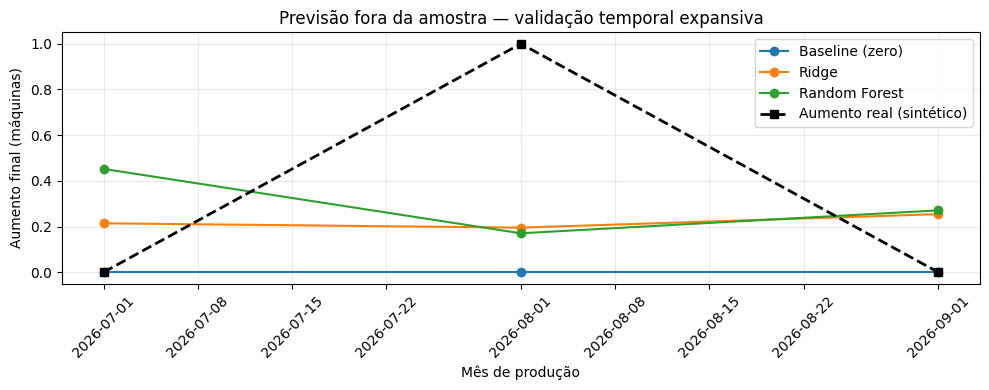

Modelo com menor MAE neste teste: Baseline (zero)
Meses de teste: 3
Diagnóstico: os modelos treinados NÃO superaram o baseline em MAE.
Limitações: dados sintéticos; uma máquina; PNs dependentes; poucos meses de treino/teste; previsões sem intervalo de confiança calibrado.
Arquivos gerados: previsoes_ml_piloto.csv, metricas_ml_piloto.csv


In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
for nome,grupo in previsoes_ml.groupby('Modelo',sort=False):
    ax.plot(grupo['Mes_producao'],grupo['Previsao'],marker='o',label=nome)
real = previsoes_ml[previsoes_ml['Modelo'].eq('Baseline (zero)')]
ax.plot(real['Mes_producao'],real['Real'],color='black',linewidth=2,linestyle='--',marker='s',label='Aumento real (sintético)')
ax.set(title='Previsão fora da amostra — validação temporal expansiva',ylabel='Aumento final (máquinas)',xlabel='Mês de produção')
ax.legend();ax.grid(alpha=.25);plt.xticks(rotation=45);plt.tight_layout();plt.show()
melhor=metricas_ml.iloc[0]
print('Modelo com menor MAE neste teste:',melhor['Modelo'])
print('Meses de teste:',int(melhor['Meses_teste']))
if melhor['Modelo']=='Baseline (zero)':
    print('Diagnóstico: os modelos treinados NÃO superaram o baseline em MAE.')
else:
    print('Diagnóstico: houve menor MAE nesta simulação, mas o histórico de teste é curto e não comprova generalização.')
print('Limitações: dados sintéticos; uma máquina; PNs dependentes; poucos meses de treino/teste; previsões sem intervalo de confiança calibrado.')
previsoes_ml.to_csv('previsoes_ml_piloto.csv',index=False,encoding='utf-8-sig')
metricas_ml.to_csv('metricas_ml_piloto.csv',index=False,encoding='utf-8-sig')
print('Arquivos gerados: previsoes_ml_piloto.csv, metricas_ml_piloto.csv')


## 9. Relatório PDF executivo e data sheets para apresentação

Esta célula restaura o **PDF automático** do projeto original: objetivo, metodologia, PNs, LT × final × pico, variabilidade, necessidade adicional, trajetória mensal, estoque de segurança e módulo ML. Exporta também os dados tabulares em CSV para consulta. No Colab, os arquivos ficam na aba **Arquivos** e podem ser baixados.


In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('reportlab') is None:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','reportlab'])
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak, KeepTogether
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.units import cm
from io import BytesIO

PDF_SAIDA = 'Relatorio_Variabilidade_MAQ-001_Sintetico_ML.pdf'
AZUL=colors.HexColor('#17375E')
styles=getSampleStyleSheet()
styles.add(ParagraphStyle(name='TituloPiloto',parent=styles['Title'],fontSize=17,leading=22,textColor=AZUL,spaceAfter=14))
styles.add(ParagraphStyle(name='SecaoPiloto',parent=styles['Heading2'],fontSize=12,leading=15,textColor=AZUL,spaceBefore=9,spaceAfter=7))
styles.add(ParagraphStyle(name='PequenoPiloto',parent=styles['BodyText'],fontSize=8,leading=11))

def ptxt(s):return Paragraph(str(s),styles['PequenoPiloto'])
def tab_pdf(headers,rows,widths=None):
    dados=[[ptxt(h) for h in headers]]+[[ptxt(str(v)) for v in row] for row in rows]
    t=Table(dados,colWidths=widths,repeatRows=1,hAlign='CENTER')
    t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),AZUL),('TEXTCOLOR',(0,0),(-1,0),colors.white),('BACKGROUND',(0,1),(-1,-1),colors.whitesmoke),('GRID',(0,0),(-1,-1),.25,colors.HexColor('#B0B8C2')),('VALIGN',(0,0),(-1,-1),'MIDDLE'),('LEFTPADDING',(0,0),(-1,-1),6),('RIGHTPADDING',(0,0),(-1,-1),6),('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5)]))
    # Header paragraphs need white foreground; use simple strings in header.
    dados[0]=[Paragraph('<font color="white"><b>'+str(h)+'</b></font>',styles['PequenoPiloto']) for h in headers]
    return t

def fig_pdf(fig,w=23):
    b=BytesIO();fig.savefig(b,format='png',dpi=145,bbox_inches='tight');b.seek(0)
    im=Image(b);im.drawWidth=w*cm;im.drawHeight=im.imageHeight*im.drawWidth/im.imageWidth
    return im

doc=SimpleDocTemplate(PDF_SAIDA,pagesize=landscape(A4),rightMargin=1.5*cm,leftMargin=1.5*cm,topMargin=1.4*cm,bottomMargin=1.4*cm)
story=[]
def h(s):story.append(Paragraph(s,styles['SecaoPiloto']))
def par(s):story.append(Paragraph(s,styles['BodyText']));story.append(Spacer(1,7))

story.append(Paragraph('RELATÓRIO DE VARIABILIDADE PÓS-LEAD TIME',styles['TituloPiloto']))
par('Piloto MAQ-001 — 13 Part Numbers fictícios — Dados 100% sintéticos — Extensão com Machine Learning.')
h('1. Objetivo e metodologia')
par('Medir como o plano de produção se altera após a decisão de compra (lead time de cinco meses), analisar revisões intermediárias e simular políticas de estoque de segurança. Para cada mês, utiliza-se o plano disponível em LT=5, a última revisão e o pico posterior. A análise é demonstrativa, não operacional.')
h('2. Base de Part Numbers do piloto')
story.append(tab_pdf(['Fornecedor fictício','Part Number','Aplicação','Qtd./máquina'],[[r['Fornecedor'],r['Part Number'],r['Aplicação'],int(r['Qtd./máquina'])] for _,r in datasheet.iterrows()],[5*cm,5*cm,8*cm,3*cm]))
story.append(PageBreak())
h('3. Resultado — Lead Time × Plano Final × Pico')
par(f'Data de corte: {DATA_CORTE:%d/%m/%Y}. Análise histórica restrita a {len(base)} meses de produção encerrados com plano no LT e fechamento disponível. Meses futuros e em andamento são excluídos.')
par(f"Erro médio LT→final: {base['Erro_LT_Final'].mean():.2f} máquina(s); erro absoluto médio: {base['Erro_LT_Final'].abs().mean():.2f} máquina(s). O pico intermediário pode desaparecer no plano final.")
fig,ax=plt.subplots(figsize=(11.5,4.2));ax.plot(base.index,base['Plano_LT'],marker='o',label='Demanda no LT');ax.plot(base.index,base['Pico_pos_LT'],marker='^',label='Pico pós-LT');ax.plot(base.index,base['Plano_final'],marker='s',label='Final');ax.legend();ax.grid(alpha=.25);ax.set(ylabel='Máquinas',title='Trajetória do plano de produção — MAQ-001');plt.xticks(rotation=45);fig.tight_layout();story.append(fig_pdf(fig));plt.close(fig)
story.append(PageBreak())
h('4. Variabilidade após o Lead Time')
story.append(tab_pdf(['Indicador','Resultado'],[[r['Indicador'],r['Resultado']] for _,r in indicadores.iterrows()],[12*cm,7*cm]))
fig,ax=plt.subplots(figsize=(10,3.5));ax.bar(base.index,base['Amplitude_pos_LT'],width=18);ax.set(title='Amplitude da demanda pós-LT',ylabel='Máquinas');ax.grid(axis='y',alpha=.2);plt.xticks(rotation=45);fig.tight_layout();story.append(fig_pdf(fig,20));plt.close(fig)
story.append(PageBreak())
h('5. Necessidade adicional observada após LT')
par('O aumento máximo positivo representa o pico posterior menos a demanda conhecida no LT. Este indicador revela volatilidade e não equivale necessariamente a uma falta de material.')
fig,ax=plt.subplots(figsize=(11,4));ax.bar(base.index,base['Aumento_maximo_pos_LT'],width=18);ax.set(title='Aumento máximo positivo pós-LT',ylabel='Máquinas');ax.grid(axis='y',alpha=.2);plt.xticks(rotation=45);fig.tight_layout();story.append(fig_pdf(fig));plt.close(fig)
story.append(PageBreak())
h('6. Trajetória mensal — PN sintético de referência')
ref=datasheet['Part Number'].iloc[0];par('PN: '+ref+' — consumo unitário por máquina. Os demais PNs compartilham o mesmo plano neste piloto.')
headers=['Mês','LT','Mín.','Pico','Amplitude','Aumento máx.','Final','Erro LT→Final']
rows=[]
for mes,r in trajetoria_mensal.iterrows():
    rows.append([mes.strftime('%m/%Y')]+[int(r[c]) for c in ['Plano_LT','Min_pos_LT','Pico_pos_LT','Amplitude_pos_LT','Aumento_maximo_pos_LT','Plano_final','Erro_LT_Final']])
story.append(tab_pdf(headers,rows,[3*cm]+[2.8*cm]*7))
story.append(PageBreak())
h('7. Simulação empírica de estoque de segurança')
par(f'Para a meta ilustrativa de cobertura histórica de {ALVO_COBERTURA}%, o menor ES observado foi {es_demo} unidade(s) por PN (consumo 1). A política considera o aumento final; os picos são analisados separadamente. Cobertura histórica não é nível de serviço futuro garantido.')
story.append(tab_pdf(['ES (un.)','Cobertura final (%)','Cobertura pico (%)','Faltas finais (un.)'],[[int(r['ES_maquinas']),f"{r['Cobertura_final_%']:.1f}",f"{r['Cobertura_pico_%']:.1f}",int(r['Faltas_finais_total'])] for _,r in politicas.iterrows()],[4*cm]*4))
story.append(Spacer(1,10))
h('8. Machine Learning — validação temporal')
story.append(tab_pdf(['Modelo','Meses teste','MAE','RMSE'],[[r['Modelo'],int(r['Meses_teste']),f"{r['MAE']:.3f}",f"{r['RMSE']:.3f}"] for _,r in metricas_ml.iterrows()],[6*cm,4*cm,4*cm,4*cm]))
par('Baseline: previsão de zero aumento. Ridge e Random Forest utilizam apenas informações disponíveis na data da decisão. Amostra temporal pequena e dados sintéticos impedem inferência de desempenho empresarial.')
h('9. Conclusões do piloto')
par('O protótipo executa importação, validação, análise da trajetória pós-LT, conversão para demanda por PN, simulação de estoque de segurança e avaliação comparativa de algoritmos. Picos intermediários podem ser superiores à demanda final. Não há validação operacional real, e os 13 PNs não são amostras independentes. Antes de recomendações reais, são necessários histórico autorizado, validação temporal ampliada e análise de custos.')

def rodape(canvas,doc):
    canvas.setFont('Helvetica',8);canvas.setFillColor(AZUL)
    canvas.drawString(1.5*cm,.8*cm,'Projeto de Variabilidade de Planejamento — MAQ-001 | DADOS SINTÉTICOS')
    canvas.drawRightString(28*cm,.8*cm,f'Página {doc.page}')
doc.build(story,onFirstPage=rodape,onLaterPages=rodape)
# Datasheets exportáveis e resultados para auditoria.
datasheet.to_csv('datasheet_pns_sinteticos.csv',index=False,encoding='utf-8-sig')
trajetoria_mensal.to_csv('trajetoria_mensal_piloto.csv',index_label='Mes_producao',encoding='utf-8-sig')
indicadores.to_csv('indicadores_variabilidade_piloto.csv',index=False,encoding='utf-8-sig')
politicas_pn.to_csv('estoque_seguranca_por_pn_piloto.csv',index=False,encoding='utf-8-sig')
print('Relatório gerado:',PDF_SAIDA)
print('Data sheets e resultados CSV exportados.')

# Download automático do relatório quando executado no Google Colab.
# Fora do Colab, o PDF permanece salvo no diretório de execução.
import os
if not os.path.isfile(PDF_SAIDA):
    raise FileNotFoundError(f"O relatório não foi encontrado: {PDF_SAIDA}")
print(f"PDF disponível: {os.path.abspath(PDF_SAIDA)} ({os.path.getsize(PDF_SAIDA):,} bytes)")
try:
    from google.colab import files as colab_files
except ImportError:
    print("Ambiente local: abra o PDF no caminho informado acima.")
else:
    colab_files.download(PDF_SAIDA)


Relatório gerado: Relatorio_Variabilidade_MAQ-001_Sintetico_ML.pdf
Data sheets e resultados CSV exportados.
PDF disponível: /content/Relatorio_Variabilidade_MAQ-001_Sintetico_ML.pdf (218,713 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusão e próximos passos empresariais

- **Funcionalidade demonstrada:** ingestão, auditoria, cálculo de variações, simulação de ES e comparação supervisionada com validação temporal.
- **Não demonstrado:** eficácia operacional em dados reais, precisão futura ou cobertura de 95% fora da amostra.
- **Próxima aplicação real:** executar com histórico empresarial autorizado, revisar disponibilidade das variáveis na data de decisão, ampliar meses de teste, comparar custos de falta e excesso, e monitorar desempenho antes de utilizar recomendações de compra.
- **Transparência acadêmica:** dados compartilhados são integralmente sintéticos e representam um caso de uso inspirado em uma operação real; não constituem um dataset público real observado.


- **Ajuste de hiperparâmetros:** Ridge e Random Forest foram avaliados com grades pequenas e validação walk-forward somente no histórico anterior a cada mês previsto; resultados ainda dependem de validação com dados reais.

## 11. Resumo executivo automático — estoque de segurança e Machine Learning

Esta seção consolida **os resultados calculados na execução atual**, sem valores fixos inseridos manualmente.

- **Estoque de segurança (ES):** menor nível inteiro que atende à meta ilustrativa de cobertura histórica dos aumentos **finais** após o lead time. A curva de picos é apresentada separadamente e pode exigir cobertura diferente.
- **Machine Learning:** métricas de previsão fora da amostra, calculadas em teste temporal. Menor MAE e menor RMSE podem pertencer a modelos diferentes.
- **Unidade de análise:** meses elegíveis, não quantidade de PNs nem total de revisões. Os meses de ML podem ser menos numerosos devido às defasagens.
- **Interpretação:** resultados exploratórios sobre base sintética; a cobertura retrospectiva não garante nível de serviço futuro nem representa autorização de compra.

Execute todas as células anteriores antes desta seção. Os arquivos CSV de resumo são gerados ao final.


In [ ]:
# Resumo executivo calculado a partir das tabelas efetivamente produzidas acima.
# Não modifica o cálculo de ES, o treinamento dos modelos ou os dados de entrada.
from IPython.display import display
import pandas as pd
import numpy as np

necessarias = ['resumo', 'base', 'politicas', 'es_demo', 'ALVO_COBERTURA',
               'politicas_pn', 'ml', 'metricas_ml']
faltantes = [nome for nome in necessarias if nome not in globals()]
if faltantes:
    raise RuntimeError('Execute as células anteriores antes do resumo: ' + ', '.join(faltantes))

n_total = int(len(resumo))
n_es = int(len(base))
n_abertos = int((~resumo['Elegível']).sum())
n_ml = int(len(ml))
n_teste = int(metricas_ml['Meses_teste'].iloc[0])
cob_final = float((base['Aumento_final'] <= es_demo).mean() * 100)
cob_pico = float((base['Aumento_pico'] <= es_demo).mean() * 100)
dist = (base['Aumento_final'].value_counts().sort_index()
        .rename_axis('Aumento_final_maquinas').reset_index(name='Meses'))
dist['Frequencia_%'] = 100 * dist['Meses'] / n_es

# Confere que a política demonstrativa é realmente a menor que alcança a meta.
elegiveis_es = politicas.loc[politicas['Cobertura_final_%'] >= ALVO_COBERTURA]
assert not elegiveis_es.empty, 'Nenhum ES candidato atingiu a cobertura-alvo.'
assert int(elegiveis_es.iloc[0]['ES_maquinas']) == int(es_demo), 'ES e tabela de políticas divergentes.'
assert int(dist['Meses'].sum()) == n_es, 'Distribuição de aumentos inconsistente.'
assert n_es + n_abertos == n_total, 'Contagem de meses inconsistentes.'
assert metricas_ml['Meses_teste'].nunique() == 1, 'Modelos com janelas de teste distintas.'

print('=== RESUMO EXECUTIVO | PILOTO SINTÉTICO MAQ-001 ===')
print(f'Base total: {n_total} meses | elegíveis para ES: {n_es} | não consolidados: {n_abertos}')
print(f'Observações disponíveis para ML após defasagens: {n_ml} | meses de teste: {n_teste}')
print(f'ES demonstrativo: {es_demo} máquinas equivalentes')
print(f'Cobertura histórica FINAL: {cob_final:.1f}% | meta ilustrativa: {ALVO_COBERTURA}%')
print(f'Cobertura histórica do PICO pós-LT no mesmo ES: {cob_pico:.1f}%')
print('\nDistribuição dos aumentos finais após LT:')
display(dist.round(2))
print('\nES por PN (considerando consumo específico):')
display(politicas_pn[['PN sintético', 'Qtd por máquina', 'ES_simulado_un', 'Cobertura_historica_%']])
print('\nComparação de modelos — teste temporal:')
display(metricas_ml.round(3))
melhor_mae = metricas_ml.loc[metricas_ml['MAE'].idxmin(), 'Modelo']
melhor_rmse = metricas_ml.loc[metricas_ml['RMSE'].idxmin(), 'Modelo']
print(f'Menor MAE: {melhor_mae} | menor RMSE: {melhor_rmse}')
print('\nATENÇÃO: base sintética, teste temporal reduzido e cobertura retrospectiva.')
print('O ES demonstrativo não é uma recomendação operacional nem garante serviço futuro de 95%.')

resumo_executivo = pd.DataFrame([
    {'Indicador':'Meses totais na base', 'Valor':n_total, 'Unidade':'meses'},
    {'Indicador':'Meses elegíveis para ES', 'Valor':n_es, 'Unidade':'meses'},
    {'Indicador':'Meses não consolidados', 'Valor':n_abertos, 'Unidade':'meses'},
    {'Indicador':'Observações disponíveis para ML', 'Valor':n_ml, 'Unidade':'meses'},
    {'Indicador':'Meses de teste ML', 'Valor':n_teste, 'Unidade':'meses'},
    {'Indicador':'ES empírico demonstrativo', 'Valor':int(es_demo), 'Unidade':'máquinas equivalentes'},
    {'Indicador':'Cobertura histórica final', 'Valor':round(cob_final,2), 'Unidade':'%'},
    {'Indicador':'Cobertura histórica pico pós-LT', 'Valor':round(cob_pico,2), 'Unidade':'%'},
    {'Indicador':'Meta ilustrativa de cobertura', 'Valor':ALVO_COBERTURA, 'Unidade':'%'},
    {'Indicador':'Modelo com menor MAE', 'Valor':melhor_mae, 'Unidade':'modelo'},
    {'Indicador':'Modelo com menor RMSE', 'Valor':melhor_rmse, 'Unidade':'modelo'},
])
resumo_executivo.to_csv('resumo_executivo_MAQ001.csv', index=False, encoding='utf-8-sig')
dist.to_csv('distribuicao_aumentos_MAQ001.csv', index=False, encoding='utf-8-sig')
print('\nArquivos gerados: resumo_executivo_MAQ001.csv e distribuicao_aumentos_MAQ001.csv')


=== RESUMO EXECUTIVO | PILOTO SINTÉTICO MAQ-001 ===
Base total: 24 meses | elegíveis para ES: 21 | não consolidados: 3
Observações disponíveis para ML após defasagens: 15 | meses de teste: 3
ES demonstrativo: 2 máquinas equivalentes
Cobertura histórica FINAL: 100.0% | meta ilustrativa: 95%
Cobertura histórica do PICO pós-LT no mesmo ES: 90.5%

Distribuição dos aumentos finais após LT:


,Aumento_final_maquinas,Meses,Frequencia_%
0,0.0,15,71.43
1,1.0,4,19.05
2,2.0,2,9.52



ES por PN (considerando consumo específico):


,PN sintético,Qtd por máquina,ES_simulado_un,Cobertura_historica_%
0,PN-0001,1,2,100.0
1,PN-0002,1,2,100.0
2,PN-0003,1,2,100.0
3,PN-0004,1,2,100.0
4,PN-0005,1,2,100.0
5,PN-0006,1,2,100.0
6,PN-0007,1,2,100.0
7,PN-0008,1,2,100.0
8,PN-0009,1,2,100.0
9,PN-0010,1,2,100.0



Comparação de modelos — teste temporal:


,Modelo,Meses_teste,MAE,RMSE,Faltas_simuladas_un,Excesso_simulado_un
0,Baseline (zero),3,0.333,0.577,1.0,0.0
1,Ridge,3,0.424,0.503,0.0,2.0
2,Random Forest,3,0.518,0.567,0.0,2.0


Menor MAE: Baseline (zero) | menor RMSE: Ridge

ATENÇÃO: base sintética, teste temporal reduzido e cobertura retrospectiva.
O ES demonstrativo não é uma recomendação operacional nem garante serviço futuro de 95%.

Arquivos gerados: resumo_executivo_MAQ001.csv e distribuicao_aumentos_MAQ001.csv
